# **EDUNET FOUNDATION**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Lab: Sentiment Analysis: Movie Review Sentiment Prediction by using RNN​**

In [2]:
import pandas as pd
import numpy as np

In [3]:
from zipfile import ZipFile
file_name = "/content/drive/MyDrive/Day 4 Lab Notebooks/imdb.zip"

with ZipFile(file_name,'r') as zip:
  zip.extractall()
  print('Done')

Done


In [4]:
# Load the dataset
imdb = pd.read_csv('/content/imdb.csv', sep='\t',encoding='latin-1')
imdb.head()

,id,review,sentiment
0,5814_8,With all this stuff going down at the moment w...,1
1,2381_9,"\The Classic War of the Worlds\"" by Timothy Hi...",1
2,7759_3,The film starts with a manager (Nicholas Bell)...,0
3,3630_4,It must be assumed that those who praised this...,0
4,9495_8,Superbly trashy and wondrously unpretentious 8...,1


In [5]:
imdb.shape

(22500, 3)

In [6]:
df = imdb.head(15000).copy()

# Encode the sentiment labels
#df['sentiment'] = df['sentiment'].replace({'positive': 1, 'negative': 0})
# Drop the 'id' column from the DataFrame
df.drop('id', axis=1, inplace=True)

In [7]:
df.head()

,review,sentiment
0,With all this stuff going down at the moment w...,1
1,"\The Classic War of the Worlds\"" by Timothy Hi...",1
2,The film starts with a manager (Nicholas Bell)...,0
3,It must be assumed that those who praised this...,0
4,Superbly trashy and wondrously unpretentious 8...,1


In [8]:
import re
# Preprocess the text data
def preprocess_text(text):
    text = text.lower()
    text = re.sub('<br />', ' ', text)
    text = re.sub('[^a-zA-Z]', ' ', text)
    return text

df['review'] = df['review'].apply(preprocess_text)

In [9]:
df.head()

,review,sentiment
0,with all this stuff going down at the moment w...,1
1,the classic war of the worlds by timothy hi...,1
2,the film starts with a manager nicholas bell ...,0
3,it must be assumed that those who praised this...,0
4,superbly trashy and wondrously unpretentious ...,1


![RNN Explination 11.png](<attachment:RNN Explination 11.png>)
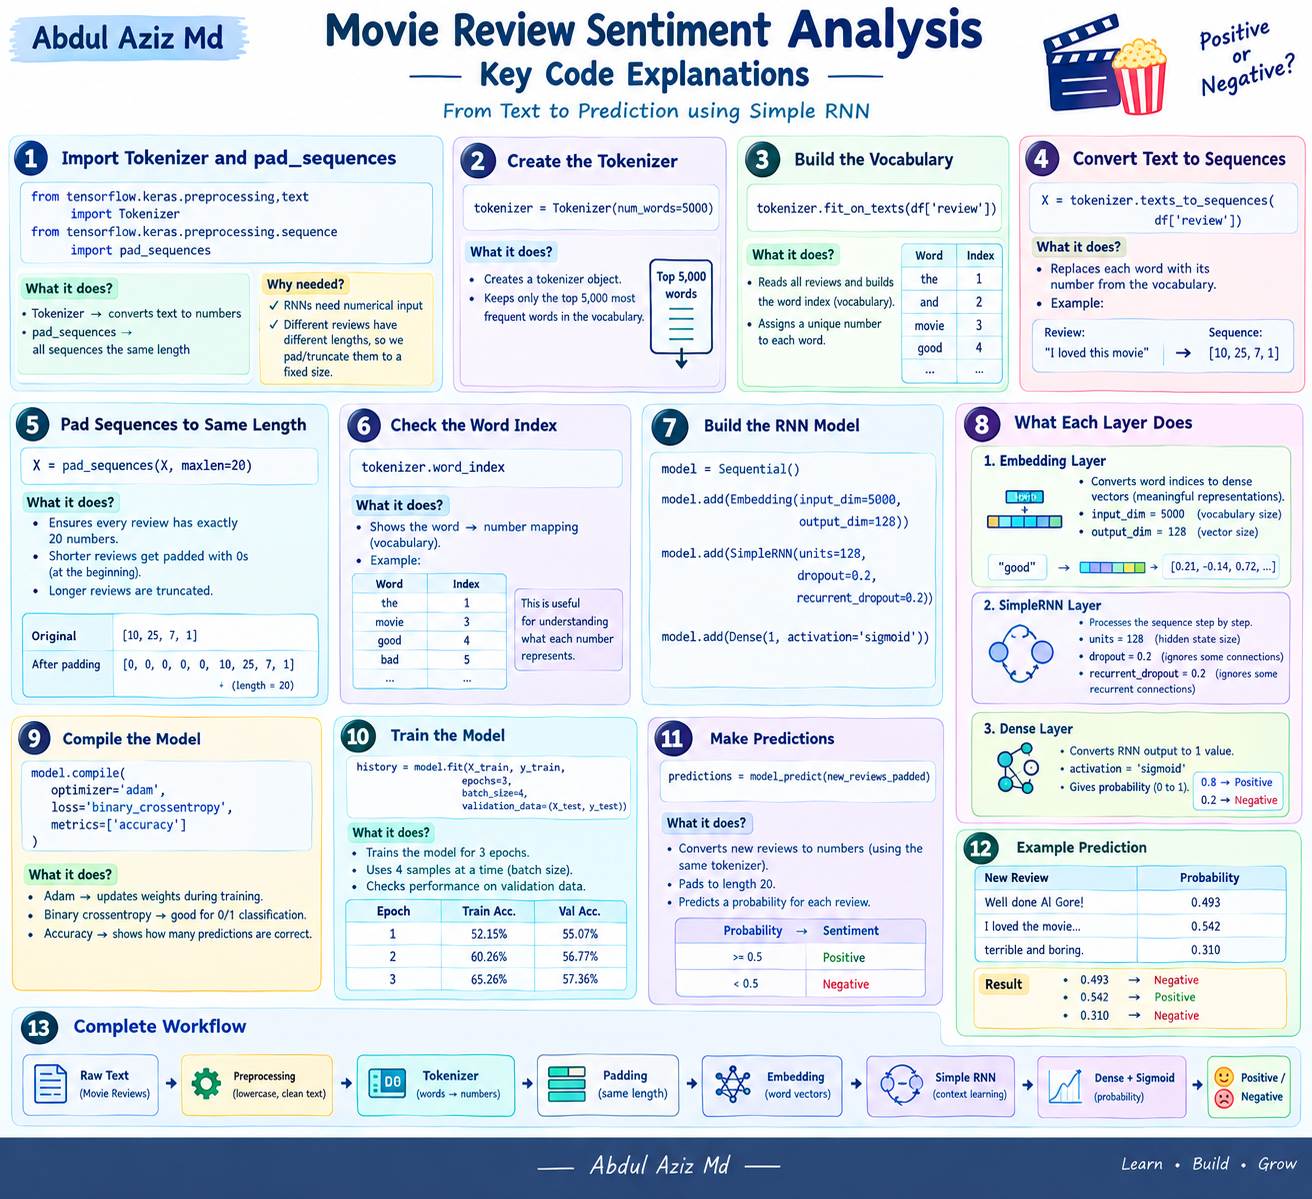

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Tokenization
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(df['review'])
X = tokenizer.texts_to_sequences(df['review'])
X = pad_sequences(X, maxlen=20)

In [11]:
X[0]

array([   6,  349,   34,  581,  331,   18,  373,  217,   41,   29,    4,
          1,   88,    9,  426,   24,    6,   23,    1, 1441], dtype=int32)

In [12]:
tokenizer.word_index

{'the': 1,
 'and': 2,
 'a': 3,
 'of': 4,
 'to': 5,
 'is': 6,
 'it': 7,
 'in': 8,
 'i': 9,
 'this': 10,
 'that': 11,
 's': 12,
 'was': 13,
 'as': 14,
 'for': 15,
 'with': 16,
 'movie': 17,
 'but': 18,
 'film': 19,
 'you': 20,
 't': 21,
 'on': 22,
 'not': 23,
 'he': 24,
 'his': 25,
 'are': 26,
 'have': 27,
 'be': 28,
 'one': 29,
 'all': 30,
 'at': 31,
 'they': 32,
 'by': 33,
 'an': 34,
 'who': 35,
 'so': 36,
 'from': 37,
 'like': 38,
 'there': 39,
 'her': 40,
 'or': 41,
 'just': 42,
 'about': 43,
 'out': 44,
 'has': 45,
 'if': 46,
 'what': 47,
 'some': 48,
 'good': 49,
 'can': 50,
 'when': 51,
 'she': 52,
 'more': 53,
 'very': 54,
 'up': 55,
 'even': 56,
 'no': 57,
 'time': 58,
 'my': 59,
 'would': 60,
 'only': 61,
 'which': 62,
 'really': 63,
 'story': 64,
 'their': 65,
 'see': 66,
 'had': 67,
 'we': 68,
 'were': 69,
 'well': 70,
 'me': 71,
 'than': 72,
 'much': 73,
 'bad': 74,
 'people': 75,
 'been': 76,
 'get': 77,
 'because': 78,
 'will': 79,
 'do': 80,
 'also': 81,
 'into': 82,
 'ot

In [13]:
tokenizer.sequences_to_texts([X[0]])

['is either an extremely nice but stupid guy or one of the most i hope he is not the latter']

In [14]:
tokenizer.index_word

{1: 'the',
 2: 'and',
 3: 'a',
 4: 'of',
 5: 'to',
 6: 'is',
 7: 'it',
 8: 'in',
 9: 'i',
 10: 'this',
 11: 'that',
 12: 's',
 13: 'was',
 14: 'as',
 15: 'for',
 16: 'with',
 17: 'movie',
 18: 'but',
 19: 'film',
 20: 'you',
 21: 't',
 22: 'on',
 23: 'not',
 24: 'he',
 25: 'his',
 26: 'are',
 27: 'have',
 28: 'be',
 29: 'one',
 30: 'all',
 31: 'at',
 32: 'they',
 33: 'by',
 34: 'an',
 35: 'who',
 36: 'so',
 37: 'from',
 38: 'like',
 39: 'there',
 40: 'her',
 41: 'or',
 42: 'just',
 43: 'about',
 44: 'out',
 45: 'has',
 46: 'if',
 47: 'what',
 48: 'some',
 49: 'good',
 50: 'can',
 51: 'when',
 52: 'she',
 53: 'more',
 54: 'very',
 55: 'up',
 56: 'even',
 57: 'no',
 58: 'time',
 59: 'my',
 60: 'would',
 61: 'only',
 62: 'which',
 63: 'really',
 64: 'story',
 65: 'their',
 66: 'see',
 67: 'had',
 68: 'we',
 69: 'were',
 70: 'well',
 71: 'me',
 72: 'than',
 73: 'much',
 74: 'bad',
 75: 'people',
 76: 'been',
 77: 'get',
 78: 'because',
 79: 'will',
 80: 'do',
 81: 'also',
 82: 'into',
 83:

In [15]:
decoded_words = [tokenizer.index_word.get(i, "<UNK>") for i in X[0]]
print(decoded_words)

['is', 'either', 'an', 'extremely', 'nice', 'but', 'stupid', 'guy', 'or', 'one', 'of', 'the', 'most', 'i', 'hope', 'he', 'is', 'not', 'the', 'latter']


In [16]:
# Encode labels
y = df['sentiment'].values

In [17]:
# Split the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout

In [20]:


model = Sequential()
model.add(Embedding(input_dim=5000, output_dim=128))
model.add(SimpleRNN(units=128, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(1, activation='sigmoid'))


In [21]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [22]:
# Train the model
history = model.fit(X_train, y_train, epochs=3, batch_size=4, validation_data=(X_test, y_test))

Epoch 1/3
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.5215 - loss: 0.7038 - val_accuracy: 0.5507 - val_loss: 0.6822
Epoch 2/3
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.6026 - loss: 0.6538 - val_accuracy: 0.5677 - val_loss: 0.6859
Epoch 3/3
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.6526 - loss: 0.6095 - val_accuracy: 0.5736 - val_loss: 0.6676


In [23]:
del zip

In [24]:
# Predict sentiment for new reviews
new_reviews = [ "Well done Al Gore!","I loved the movie, it was fantastic!", "terrible and boring."]
new_reviews_preprocessed = [preprocess_text(review) for review in new_reviews]
new_reviews_sequences = tokenizer.texts_to_sequences(new_reviews_preprocessed)
new_reviews_padded = pad_sequences(new_reviews_sequences, maxlen=20)
predictions = model.predict(new_reviews_padded)

# Print raw predictions to debug
print("Raw predictions:", predictions)

# Convert predictions to "positive" or "negative"
predicted_labels = ['positive' if pred >= 0.5 else 'negative' for pred in predictions]

for review, sentiment in zip(new_reviews, predicted_labels):
    print(f'Review: "{review}" - Sentiment: {sentiment}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 531ms/step
Raw predictions: [[0.4925787 ]
 [0.5423542 ]
 [0.31020114]]
Review: "Well done Al Gore!" - Sentiment: negative
Review: "I loved the movie, it was fantastic!" - Sentiment: positive
Review: "terrible and boring." - Sentiment: negative
